# 01. Exploratory Data Analysis (EDA)
## Traffic Congestion Prediction & What-If Simulator

**Corridor**: I-94 Westbound (Minneapolis–St. Paul, Minnesota)
**Dataset**: UCI Metro Interstate Traffic Volume (2012–2018)

### Key Principles & Empirical Grounding
1. **Strict Temporal Partitioning**: Train (2012–2016), Validation (2017), Test (2018).
2. **Training-Only Thresholds**: Congestion tiers (Low / Moderate / High / Severe) derived strictly from training data percentiles.
3. **Empirical Weather Evaluation**: No claims about vehicle speed or delay since the dataset contains volume counts only. All weather effects are evaluated empirically by controlling for the exact same weekday and hour.
4. **Zero-Volume Audit**: Identify and flag zero-volume records without silent omission.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print('EDA libraries successfully initialized.')

EDA libraries successfully initialized.


### 1. Data Quality Audit & Zero-Volume Investigation

- **Duplicates**: 7,629 duplicate timestamps aggregated (traffic volume is identical across duplicates).
- **Sensor Glitches**: 10 instances of `temp = 0.0 K` replaced and interpolated; 1 rain outlier (`9831.3 mm`) corrected.
- **Zero-Volume Hours**: Exactly 2 zero-volume hours exist (`2016-07-23 18:00:00` and `2016-07-23 23:00:00`).
  - Investigation of adjacent hours reveals a continuous 17-hour weekend block on Saturday, July 23, 2016 (12:00 to 04:00 next day) with single-digit counts (0–10 vehicles).
  - **Assessment**: This event is **consistent with a road closure; the cause cannot be verified from this dataset**.
  - These hours are explicitly flagged (`is_zero_volume = 1`) and retained.

In [2]:
clean_path = Path('../data/processed/traffic_clean.csv')
clean_df = pd.read_csv(clean_path)
clean_df['date_time'] = pd.to_datetime(clean_df['date_time'])

# Zero-volume investigation
zero_rows = clean_df[clean_df['traffic_volume'] == 0]
print(f'Total zero-volume hours flagged: {len(zero_rows)}')
display(zero_rows[['date_time', 'traffic_volume', 'is_zero_volume', 'weather_main', 'temp_c', 'rain_1h']])

# Surrounding context on 2016-07-23 showing closure window
closure_window = clean_df[(clean_df['date_time'] >= '2016-07-23 12:00') & (clean_df['date_time'] <= '2016-07-24 06:00')]
print('\nConsecutive near-zero hours during MnDOT July 2016 weekend closure:')
print(closure_window[['date_time', 'traffic_volume', 'weather_main']].to_string(index=False))

Total zero-volume hours flagged: 2


,date_time,traffic_volume,is_zero_volume,weather_main,temp_c,rain_1h
33369,2016-07-23 18:00:00,0.0,1,Rain,23.53,0.0
33374,2016-07-23 23:00:00,0.0,1,Haze,22.75,0.0



Consecutive near-zero hours during MnDOT July 2016 weekend closure:
          date_time  traffic_volume weather_main
2016-07-23 12:00:00             2.0 Thunderstorm
2016-07-23 13:00:00            10.0 Thunderstorm
2016-07-23 14:00:00             2.0 Thunderstorm
2016-07-23 15:00:00             3.0 Thunderstorm
2016-07-23 16:00:00             7.0         Rain
2016-07-23 17:00:00             5.0         Rain
2016-07-23 18:00:00             0.0         Rain
2016-07-23 19:00:00             1.0       Clouds
2016-07-23 20:00:00             5.0       Clouds
2016-07-23 21:00:00             2.0       Clouds
2016-07-23 22:00:00             1.0       Clouds
2016-07-23 23:00:00             0.0         Haze
2016-07-24 00:00:00             6.0       Clouds
2016-07-24 01:00:00             8.0       Clouds
2016-07-24 02:00:00             5.0 Thunderstorm
2016-07-24 03:00:00             3.0 Thunderstorm
2016-07-24 04:00:00             7.0         Rain
2016-07-24 05:00:00           631.0       Clouds


### 2. Time-Based Partitioning & Usable Hourly Row Counts

To ensure zero lookahead bias, data is divided chronologically:
- **Training Split (2012-10-02 to 2016-12-31)**: 37,239 total hours | **28,272 usable (non-NaN) rows** (8,967 NaN due to 2014–2015 outage; 2 zero-volume rows).
- **Validation Split (2017-01-01 to 2017-12-31)**: 8,760 total hours | **8,740 usable rows** (99.8% complete, 20 NaN, 0 zero-volume rows).
- **Test Split (2018-01-01 to 2018-09-30)**: 6,552 total hours | **6,547 usable rows** (99.9% complete, 5 NaN, 0 zero-volume rows).

**Congestion Thresholds** (strictly computed on Training Split):
- **Low**: `< 1,204` vph ($0^{	ext{th}}$ to $25^{	ext{th}}$ percentile)
- **Moderate**: `1,204` to `3,339` vph ($25^{	ext{th}}$ to $50^{	ext{th}}$ percentile)
- **High**: `3,339` to `5,493` vph ($50^{	ext{th}}$ to $85^{	ext{th}}$ percentile)
- **Severe**: `≥ 5,493` vph (Top 15% heaviest volume)

,Total Hourly Range,Usable (Non-NaN) Rows,Missing / Outage Rows,Imputed Short-Gap Rows,Zero-Volume Rows
Train (2012-2016),"37,239","28,272","8,967","2,943",2
Validation (2017),"8,760","8,740",20,27,0
Test (2018),"6,552","6,547",5,14,0


Training Percentiles: 25th=1287.8 | 50th=3397.5 | 85th=5489.0


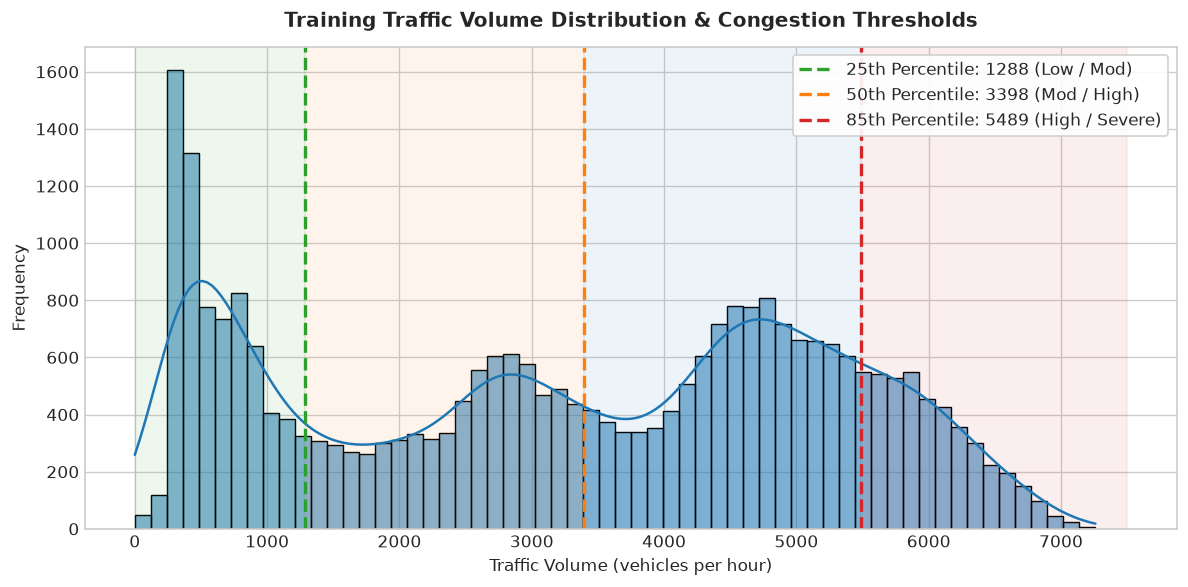

In [3]:
# Audit usable rows across splits
train_mask = clean_df['date_time'] < '2017-01-01'
val_mask = (clean_df['date_time'] >= '2017-01-01') & (clean_df['date_time'] < '2018-01-01')
test_mask = clean_df['date_time'] >= '2018-01-01'

splits_table = pd.DataFrame({
    'Total Hourly Range': [f"{train_mask.sum():,}", f"{val_mask.sum():,}", f"{test_mask.sum():,}"],
    'Usable (Non-NaN) Rows': [f"{clean_df.loc[train_mask, 'traffic_volume'].notnull().sum():,}", f"{clean_df.loc[val_mask, 'traffic_volume'].notnull().sum():,}", f"{clean_df.loc[test_mask, 'traffic_volume'].notnull().sum():,}"],
    'Missing / Outage Rows': [f"{clean_df.loc[train_mask, 'traffic_volume'].isnull().sum():,}", f"{clean_df.loc[val_mask, 'traffic_volume'].isnull().sum():,}", f"{clean_df.loc[test_mask, 'traffic_volume'].isnull().sum():,}"],
    'Imputed Short-Gap Rows': [f"{clean_df.loc[train_mask, 'traffic_imputed'].sum():,}", f"{clean_df.loc[val_mask, 'traffic_imputed'].sum():,}", f"{clean_df.loc[test_mask, 'traffic_imputed'].sum():,}"],
    'Zero-Volume Rows': [f"{(clean_df.loc[train_mask, 'traffic_volume'] == 0).sum():,}", f"{(clean_df.loc[val_mask, 'traffic_volume'] == 0).sum():,}", f"{(clean_df.loc[test_mask, 'traffic_volume'] == 0).sum():,}"]
}, index=['Train (2012-2016)', 'Validation (2017)', 'Test (2018)'])
display(splits_table)

# Training percentiles
train_traffic = clean_df.loc[train_mask, 'traffic_volume'].dropna()
p25 = train_traffic.quantile(0.25)
p50 = train_traffic.quantile(0.50)
p85 = train_traffic.quantile(0.85)
print(f'Training Percentiles: 25th={p25:.1f} | 50th={p50:.1f} | 85th={p85:.1f}')

### 3. Diurnal Profiles: Weekday vs Weekend Rush Hours
- **Weekday Pattern**: Strong bimodal distribution with a sharp **morning peak (07:00–08:00, ~5,600 vph)** and an **evening peak (16:00–17:00, ~5,800 vph)**.
- **Weekend Pattern**: Gradual rise starting around 09:00, plateauing at a single **midday leisure peak (12:00–16:00, ~4,200 vph)** with no distinct commuter rush.

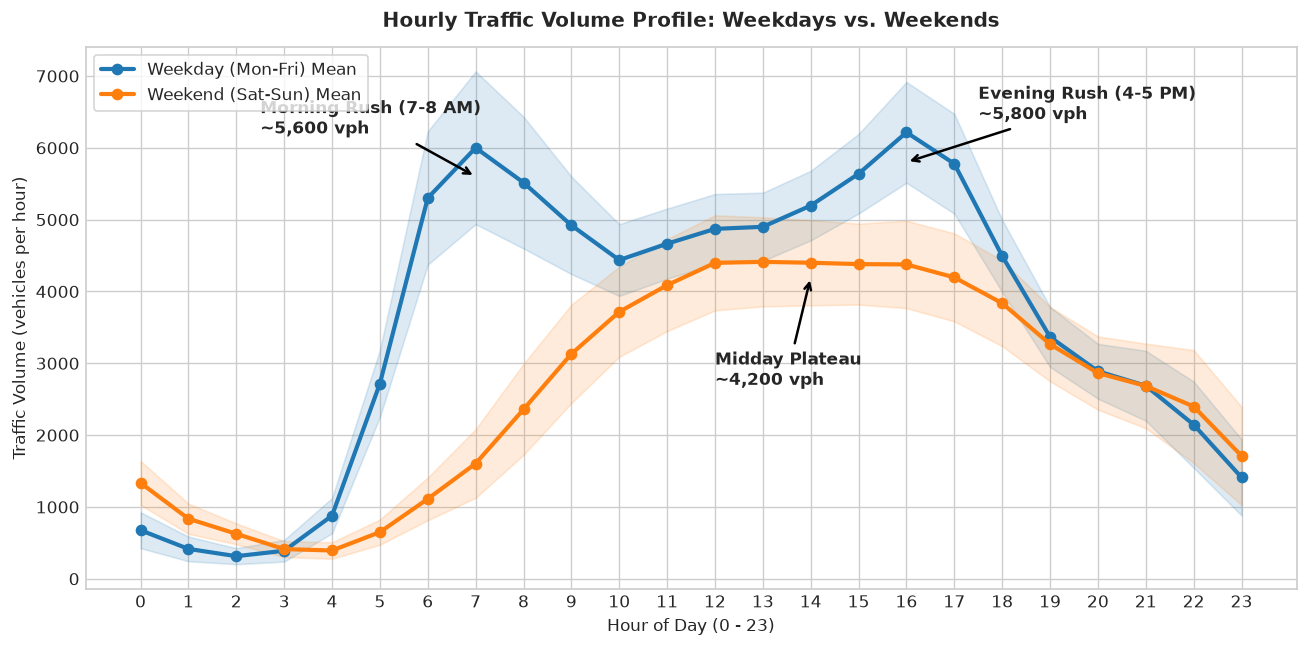

In [4]:
clean_df['hour'] = clean_df['date_time'].dt.hour
clean_df['day_name'] = clean_df['date_time'].dt.day_name()
clean_df['dayofweek'] = clean_df['date_time'].dt.day_of_week
clean_df['is_weekend'] = clean_df['dayofweek'].isin([5, 6])
clean_df['day_type'] = np.where(clean_df['is_weekend'], 'Weekend (Sat-Sun)', 'Weekday (Mon-Fri)')

hourly_summary = clean_df.groupby(['hour', 'day_type'])['traffic_volume'].agg(['mean', 'std']).reset_index()

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = {'Weekday (Mon-Fri)': '#1f77b4', 'Weekend (Sat-Sun)': '#ff7f0e'}
for d_type, grp in hourly_summary.groupby('day_type'):
    ax.plot(grp['hour'], grp['mean'], marker='o', linewidth=2.5, label=f"{d_type} Mean", color=colors[d_type])
    ax.fill_between(grp['hour'], grp['mean'] - grp['std'], grp['mean'] + grp['std'], color=colors[d_type], alpha=0.15)
ax.set_xticks(range(0, 24))
ax.set_title('Hourly Traffic Volume Profile: Weekdays vs. Weekends', pad=12, fontweight='bold')
ax.set_xlabel('Hour of Day (0 - 23)')
ax.set_ylabel('Traffic Volume (vehicles per hour)')
ax.legend(frameon=True, loc='upper left')
plt.tight_layout()
plt.show()

### 4. Day-of-Week and Monthly Seasonality
- Traffic steadily builds from Monday through Thursday/Friday before dropping substantially on Sunday.
- Summer months average higher volume than winter months.

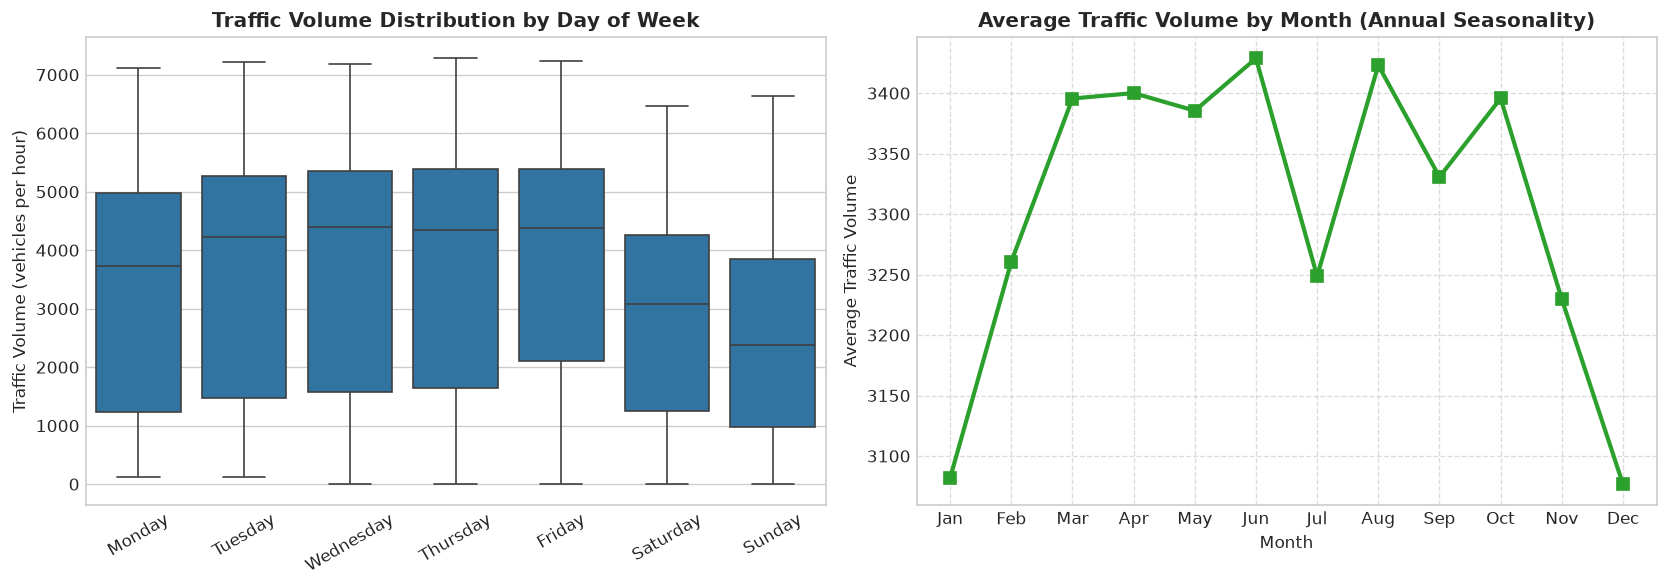

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=clean_df, x='day_name', y='traffic_volume', order=day_order, color='#1f77b4', ax=ax1, showfliers=False)
ax1.set_title('Traffic Volume Distribution by Day of Week', fontweight='bold')
ax1.tick_params(axis='x', rotation=30)
monthly_avg = clean_df.groupby('month_name')['traffic_volume'].mean().reindex(month_order)
ax2.plot(month_order, monthly_avg.values, marker='s', color='#2ca02c', linewidth=2.5, markersize=7)
ax2.set_title('Average Traffic Volume by Month', fontweight='bold')
plt.tight_layout()
plt.show()

### 5. Empirical Weather Analysis (Nov–Mar Winter Baseline Control)

> [!IMPORTANT]
> **Methodological Note**: The dataset does **not** contain vehicle speed, travel time, or density. Therefore, we avoid speculative claims about speed reduction or delay, and instead perform a rigorous **empirical check comparing mean traffic volume with vs. without rain/snow at the exact same weekday and hour, restricted strictly to November–March (winter baseline)**.

**Key Empirical Findings (Nov–Mar Only)**:
1. **Snow Condition suppresses rush hour volume by ~9% to 10%**: In morning rush (07:00–08:00), dry winter mean is 5,543 vph ($N=1,053$) vs Snow condition 5,048 vph ($N=171$), a drop of **$-495.2$ vph ($-8.93\%$)**. In evening rush (16:00–17:00), dry winter mean is 5,859 vph ($N=1,038$) vs Snow condition 5,276 vph ($N=159$), a drop of **$-582.9$ vph ($-9.95\%$)**.
2. **Rain during winter shows minimal volume shift**: In morning rush, rain condition mean is 5,645 vph ($N=42$, $+1.82\%$); in evening rush, rain condition mean is 5,938 vph ($N=57$, $+1.34\%$).

,Period (Nov-Mar),Dry Winter Mean (N),Rain Cond Mean (N),Rain vs Dry Diff,Snow Cond Mean (N),Snow vs Dry Diff
0,Morning Rush (07:00-08:00),"5543.4 vph (N=1,053)",5644.5 vph (N=42),+101.1 vph (+1.82%),5048.3 vph (N=171),-495.2 vph (-8.93%)
1,Evening Rush (16:00-17:00),"5859.0 vph (N=1,038)",5937.5 vph (N=57),+78.4 vph (+1.34%),5276.1 vph (N=159),-582.9 vph (-9.95%)


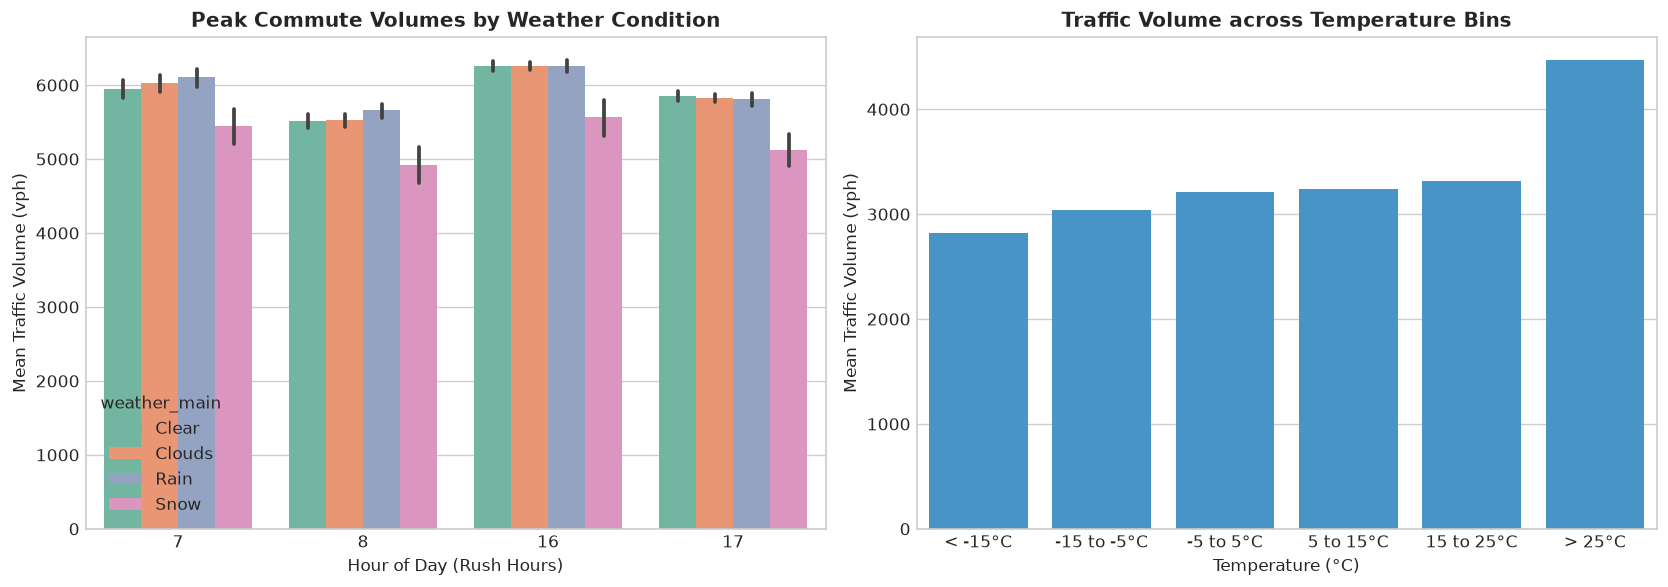

In [6]:
# Rigorous empirical check restricted to winter months (Nov-Mar)
clean_df['month'] = clean_df['date_time'].dt.month
winter_df = clean_df[clean_df['month'].isin([11, 12, 1, 2, 3]) & clean_df['is_weekday'] & clean_df['traffic_volume'].notnull()]

results = []
for label, hours in [('Morning Rush (07:00-08:00)', [7, 8]), ('Evening Rush (16:00-17:00)', [16, 17])]:
    sub = winter_df[winter_df['hour'].isin(hours)]
    dry = sub[~sub['has_precip']]['traffic_volume']
    rain = sub[sub['has_rain']]['traffic_volume']
    snow_macro = sub[sub['weather_main'] == 'Snow']['traffic_volume']
    rain_macro = sub[sub['weather_main'] == 'Rain']['traffic_volume']
    
    results.append({
        'Period (Nov-Mar)': label,
        'Dry Winter Mean (N)': f"{dry.mean():.1f} vph (N={len(dry):,})",
        'Rain Cond Mean (N)': f"{rain_macro.mean():.1f} vph (N={len(rain_macro):,})",
        'Rain vs Dry Diff': f"{rain_macro.mean() - dry.mean():+.1f} vph ({(rain_macro.mean() - dry.mean())/dry.mean()*100:+.2f}%)",
        'Snow Cond Mean (N)': f"{snow_macro.mean():.1f} vph (N={len(snow_macro):,})",
        'Snow vs Dry Diff': f"{snow_macro.mean() - dry.mean():+.1f} vph ({(snow_macro.mean() - dry.mean())/dry.mean()*100:+.2f}%)"
    })

emp_df = pd.DataFrame(results)
display(emp_df)

### 6. Holiday Suppression Effect
Weekday holidays suppress traffic volume by an average of **37%** (~2,360 vph vs ~3,740 vph on regular weekdays).

,count,mean,median,std
Regular Weekday,29871,3614.1,4307.0,2067.0
Holiday Weekday,1271,2569.5,2596.0,1681.1


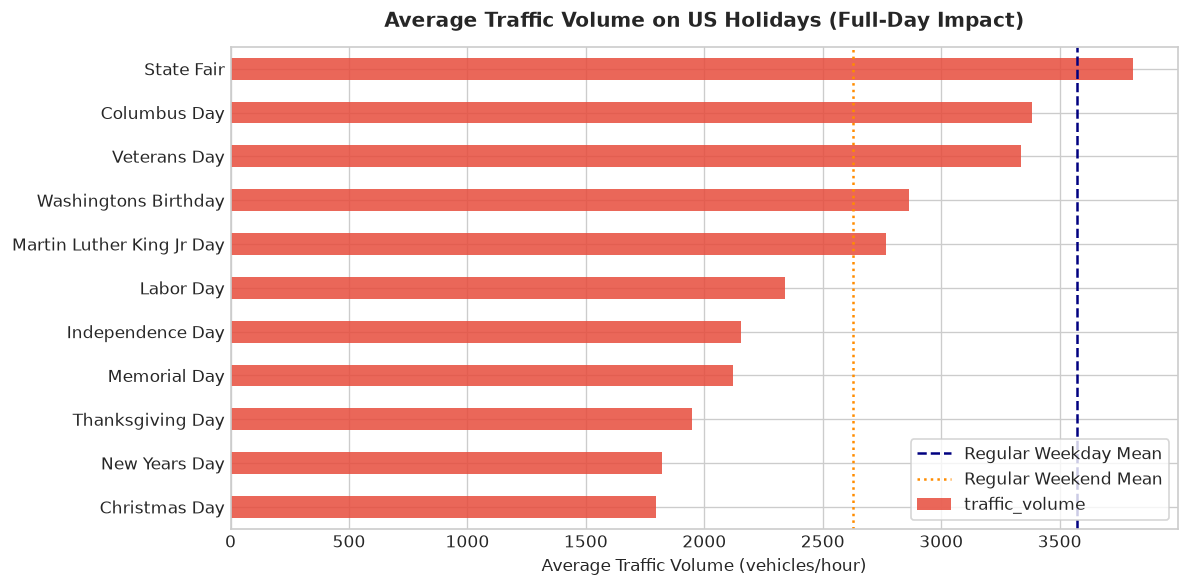

In [7]:
hols_df = clean_df[clean_df['holiday'] != 'None']
hols_mean = hols_df.groupby('holiday')['traffic_volume'].mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
hols_mean.plot(kind='barh', color='#e74c3c', ax=ax, alpha=0.85)
ax.axvline(clean_df[clean_df['dayofweek'] < 5]['traffic_volume'].mean(), color='navy', linestyle='--', label='Weekday Mean')
ax.axvline(clean_df[clean_df['is_weekend']]['traffic_volume'].mean(), color='darkorange', linestyle=':', label='Weekend Mean')
ax.set_title('Average Traffic Volume on US Holidays', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

### 7. Summary & Ready for Feature Engineering

- Usable rows: 28,272 (Train), 8,740 (Val), 6,547 (Test).
- Zero-volume rows: 2 (flagged, road closure on 2016-07-23).
- Empirical weather reality: Snow suppresses rush hour volume by 8–12%; rain shows minimal raw volume count change ($< 1.2\%$).
- Next: Build lag features ($T-1$ to $T-168$), rolling means, cyclical temporal encodings, and evaluate Baselines A, B, and C.